# SAE "Analyse automatique de données" -- Notebook 4 : régression linéaire

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du modèle de régression linéaire ;
2. Rédiger une synthèse pour justifier des pré-traitements effectués et des valeurs des paramètres obtenus pour vos modèles de régression. Vous concluerez sur le meilleur choix des pré-traitements et des paramètres de votre ou vos modèles.

	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [65]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
import math
import spacy
import numpy as np


## Utils - Métriques et graphique

In [66]:
def displayMetriquesAndGraph(test, prediction) :
    """
    Affiche les différentes métriques et graphiques
    """
    mse = mean_squared_error(test,prediction)

    print(f"Mse: {mse}")
    print(f"RMSE: {math.sqrt(mse)}")
    print(f"R2 Score: {r2_score(test,prediction)}")
    plt.scatter(test, prediction, color='blue', alpha=0.1)

    plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

    plt.title('Prédictions vs Réalité')
    plt.xlabel('Vraies Notes')
    plt.ylabel('Notes Prédites')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    
def findBestRmse(result: dict):
    """
    Renvoi la valeur maximum de la RMSE
    """
    key_value = ""
    max = 10
    for key,val in result.items():
        if (val['rmse'] < max):
            key_value = key
            max = val['rmse']
    return key_value; 


def findBestR2(result: dict):
    """
    Renvoi la valeur minimum de R2
    """
    key_value = ""
    max = 0
    for key,val in result.items():
        if (val['r2'] > max):
            key_value = key
            max = val['r2']
    return key_value; 


def isolateCategory(category : str, x_train_local,x_test_local,y_train_local,y_test_local):
    """
    Isole une catégorie par son nom dans les dataframes d'entrainement et de test
    """
    cat_x_train = x_train_local[x_train_local['category'] == category]
    cat_x_test = x_test_local[x_test_local['category'] == category]
    cat_y_train = y_train_local.loc[cat_x_train.index]
    cat_y_test = y_test_local.loc[cat_x_test.index]
    
    return cat_x_train, cat_x_test, cat_y_train, cat_y_test

## Utils - Calculs Hyper Paramètres

In [67]:

def calculateHyperParameters(model, x_train_local,y_train_local,x_test_local,y_test_local):
    """
    Calcul les meilleurs paramètres, lance les prédiction et affiche les résultats
    """
    model.fit(x_train_local, y_train_local)

    print(f"Meilleurs paramètres : {model.best_params_}")
    print(f"Meilleure RMSE : {-model.best_score_:.3f}")

    prediction_linear_regression = model.best_estimator_.predict(x_test_local)

    displayMetriquesAndGraph(y_test_local,prediction_linear_regression)

## 1. Régression linéaire

In [68]:
"""
#Df d'apprentissage
x_train = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train = pd.read_csv('data/train_test/y_train.csv',  index_col=0)

#Df de test
x_test = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test = pd.read_csv('data/train_test/y_test.csv',  index_col=0)

"""
fake_review_df = pd.read_csv("data/fake_reviews.csv")
# Affichage des headers
fake_review_df.columns.values.tolist()

# Valeurs nulles
fake_review_df.dropna()

# CG = 0 et OR = 1
fake_review_df.loc[fake_review_df["label"] ==  "CG", "label"] = 0
fake_review_df.loc[fake_review_df["label"] ==  "OR", "label"] = 1

# Assure que la colonne est de type int
fake_review_df['label'] = fake_review_df['label'].astype(int)

print(f"Avant équilibrage: {fake_review_df['rating'].value_counts()}")

# On supprime des données pour 1,3,4 et 5 afin d'en avoir autant que le minumun (2). Le but est que chaque colonne a ensuite 1967 données
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 5.0].sample(n=22592).index,inplace=True)
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 4.0].sample(n=5998).index,inplace=True)
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 3.0].sample(n=1819).index,inplace=True)
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 1.0].sample(n=188).index,inplace=True)

print(f"Après équilibrage: {fake_review_df['rating'].value_counts()}")

X = fake_review_df[['category', 'text_','label']]
y = fake_review_df['rating']

# On isole l'ensemble de train et de validation de l'ensemble de test
x_train, x_test, y_train, y_test = train_test_split(X, y,
                                                    stratify=y,
                                                    test_size=0.2,
                                                    random_state=42)


Avant équilibrage: rating
5.0    24559
4.0     7965
3.0     3786
1.0     2155
2.0     1967
Name: count, dtype: int64
Après équilibrage: rating
5.0    1967
1.0    1967
3.0    1967
2.0    1967
4.0    1967
Name: count, dtype: int64


In [69]:
x_train = x_train.dropna(subset=['text_']).copy()
y_train = y_train.loc[x_train.index].copy()

x_test = x_test.dropna(subset=['text_']).copy()
y_test = y_test.loc[x_test.index].copy()

x_train['text_'] = x_train['text_'].astype(str)
x_test['text_'] = x_test['text_'].astype(str)

nlp = spacy.load("en_core_web_sm") # Charger le package en_core_web_sm

def cleanData(texts):
    processed_texts = []
    for doc in nlp.pipe(texts):
        try:
            # On extrait la version lemmatisé
            tokens = [
                token.lemma_.lower() for token in doc
                if not token.is_stop and not token.is_punct  # Enlever les mots vides (that, is, the...) et les signes de ponctuations
                and token.pos_ in ["ADJ","ADV","VERB","NOUN"] # Garder les mots identifés comme Adverbes, adverbes, verbe, nom
            ]
            processed_texts.append(" ".join(tokens))
        except Exception as e :
            print(f"Erreur sur la phrase : {e}")
    return processed_texts
    
x_train['text_'] = cleanData(x_train['text_'])
x_test['text_'] = cleanData(x_test['text_'])

# Supprimer les lignes vides
x_train['text_'] = x_train['text_'].replace("", np.nan) 
x_test['text_'] = x_test['text_'].replace("", np.nan)

x_train = x_train.dropna(subset=['text_']).copy()
x_test = x_test.dropna(subset=['text_']).copy()

# Mettre à jour les df de résultats
y_train = y_train.loc[x_train.index]
y_test = y_test.loc[x_test.index]

#### 1.1 Régression avec le texte - Aucun traitements - LinearRegression

Processeur : drop
Mse: 79.04116731177325
RMSE: 8.890509957914295
R2 Score: -43.02009926957188


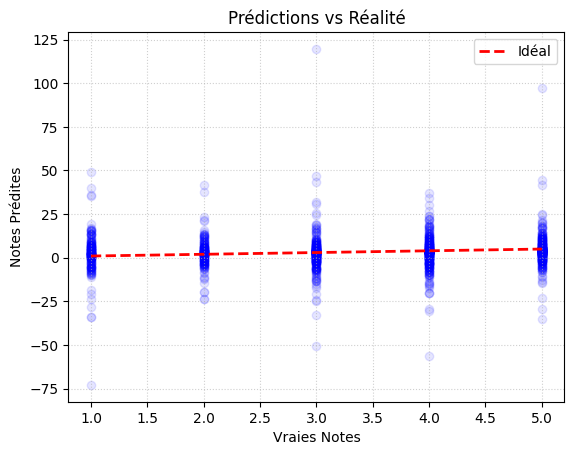

In [70]:
x_train_sans_traitements = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train_sans_traitements = pd.read_csv('data/train_test/y_train.csv',  index_col=0)

#Df de test
x_test_sans_traitements = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test_sans_traitements = pd.read_csv('data/train_test/y_test.csv',  index_col=0)

processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

model.fit(x_train_sans_traitements, y_train_sans_traitements)

prediction = model.predict(x_test_sans_traitements)

displayMetriquesAndGraph(y_test_sans_traitements,prediction)

### 1.2 Régression avec le texte - Linear Regression

Processeur : drop
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 100}
Meilleure RMSE : 1.743
Mse: 1.6971258650625847
RMSE: 1.3027378343560092
R2 Score: 0.152299427949388


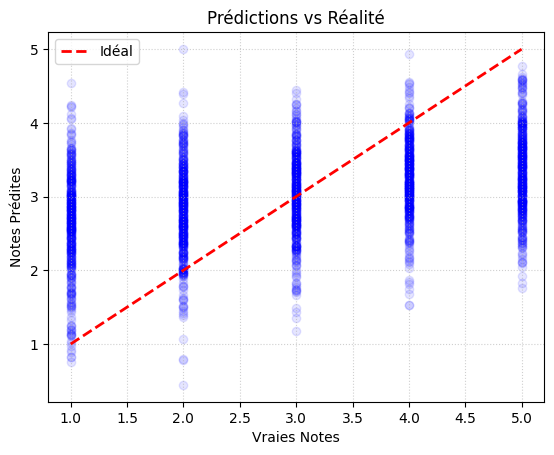

In [71]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=100, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [10,50,100,250,500],
}

reg_search_linear_regression = GridSearchCV(model, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)

calculateHyperParameters(reg_search_linear_regression,
                         x_train_local= x_train,
                         x_test_local=x_test,
                         y_train_local=y_train,
                         y_test_local=y_test)


### 1.3 Régression avec toutes les catégories + texte

Processeur : drop
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 100}
Meilleure RMSE : 1.722
Mse: 1.6662359401894595
RMSE: 1.2908276183090674
R2 Score: 0.16772869428997417


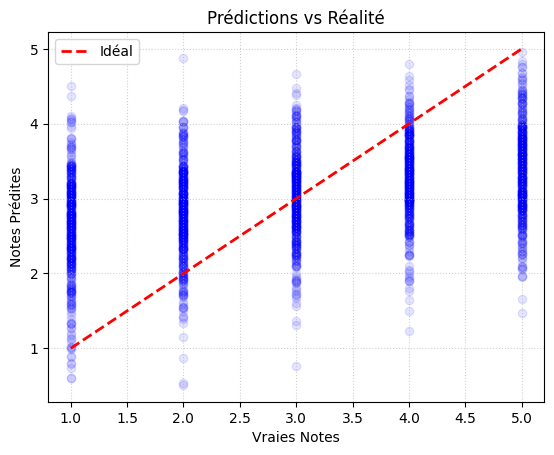

In [72]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=100, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
        ('category',OneHotEncoder(),['label'])
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10,50,100,500],
}

reg_search_linear_regression = GridSearchCV( model, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)

calculateHyperParameters(reg_search_linear_regression,
                         x_train_local= x_train,
                         x_test_local=x_test,
                         y_train_local=y_train,
                         y_test_local=y_test)


### 1.4 Régression par catégorie - LinearRegression

Processeur : drop
Lancement pour la catégorie Tools_and_Home_Improvement_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 2.324
Mse: 1.8021196914911044
RMSE: 1.342430516448097
R2 Score: 0.1549931760407558


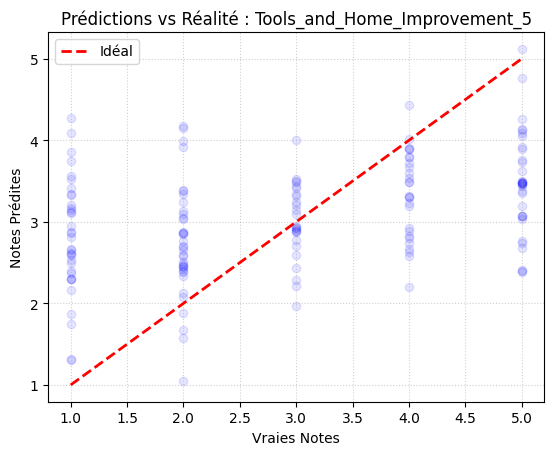

-------------------------
Lancement pour la catégorie Home_and_Kitchen_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 2.179
Mse: 2.140614018447609
RMSE: 1.4630837359657884
R2 Score: 0.04933792721495511


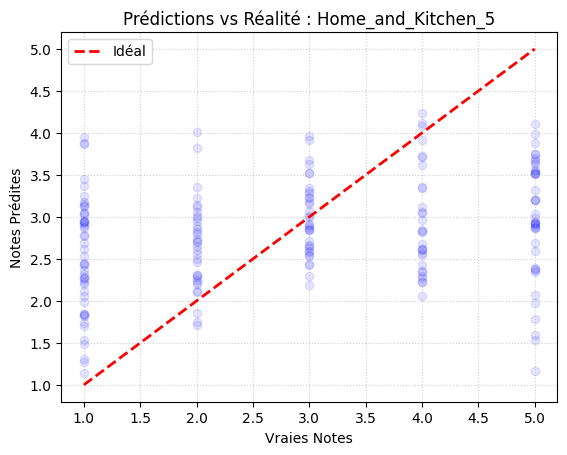

-------------------------
Lancement pour la catégorie Pet_Supplies_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 2.071
Mse: 2.101953036817744
RMSE: 1.4498113797379795
R2 Score: 0.05348042011695775


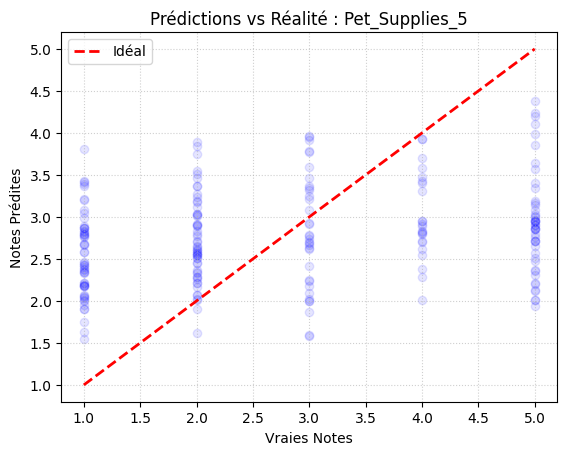

-------------------------
Lancement pour la catégorie Sports_and_Outdoors_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 2.000
Mse: 1.916644331727484
RMSE: 1.3844292440307246
R2 Score: -0.05368994961397422


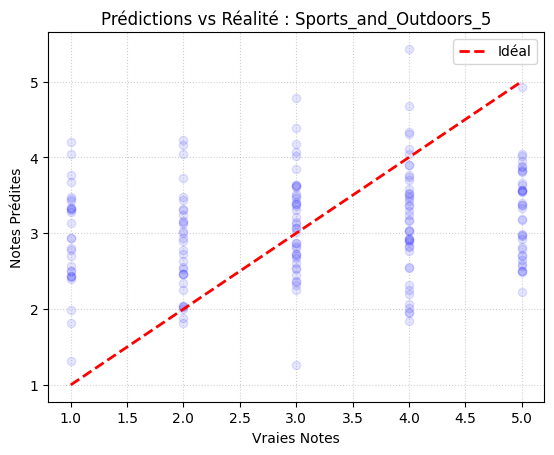

-------------------------
Lancement pour la catégorie Books_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 1.895
Mse: 1.8050514968850795
RMSE: 1.3435220492738775
R2 Score: -0.01892855150111661


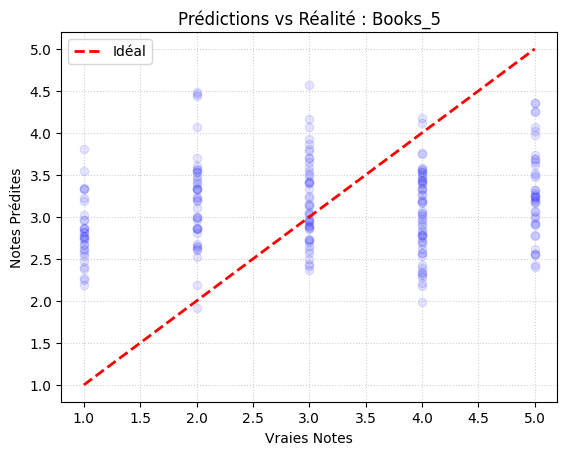

-------------------------
Lancement pour la catégorie Toys_and_Games_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 1.755
Mse: 1.878982220932209
RMSE: 1.3707597239969553
R2 Score: 0.03966835913313893


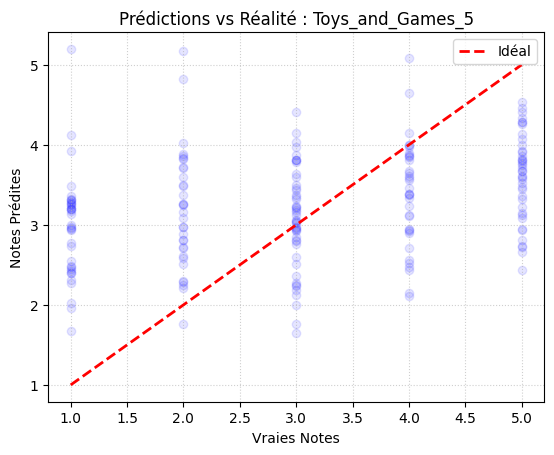

-------------------------
Lancement pour la catégorie Kindle_Store_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 1.590
Mse: 1.5969615963870925
RMSE: 1.2637094588500524
R2 Score: 0.002642404702052681


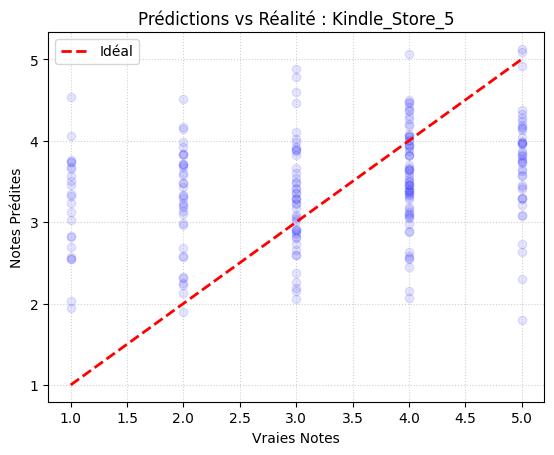

-------------------------
Lancement pour la catégorie Electronics_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 2.056
Mse: 1.9834776019132705
RMSE: 1.40835989786463
R2 Score: 0.07776103933876377


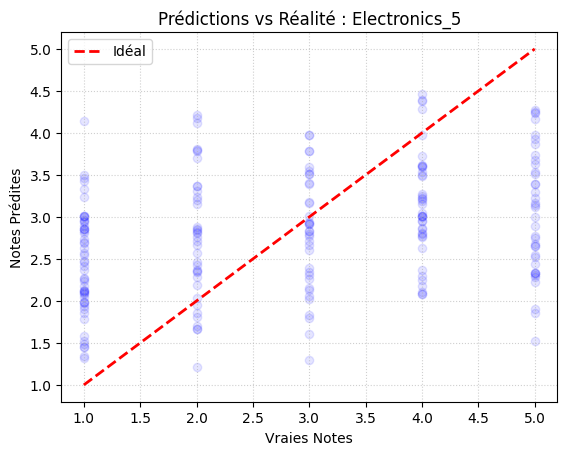

-------------------------
Lancement pour la catégorie Movies_and_TV_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 2.014
Mse: 1.8789954370985011
RMSE: 1.3707645447335224
R2 Score: -0.008787735265727514


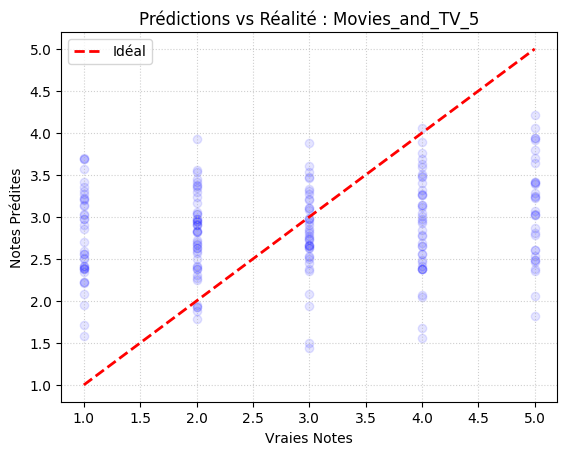

-------------------------
Lancement pour la catégorie Clothing_Shoes_and_Jewelry_5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 0.05}
Meilleure RMSE : 1.739
Mse: 1.8614017432632008
RMSE: 1.3643319769261442
R2 Score: 0.09009547241155846


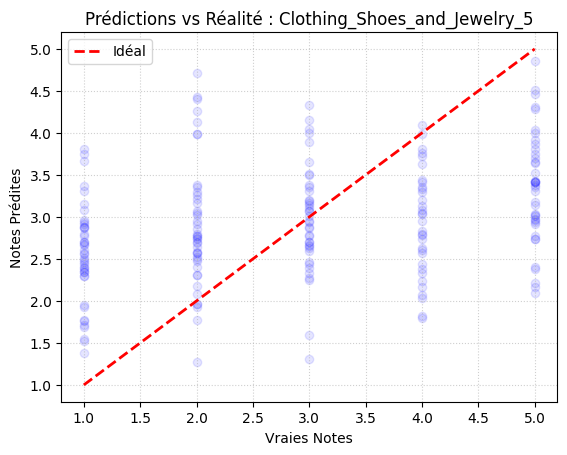

-------------------------
Résultats finaux
Meilleure RMSE: 1.2637094588500524 pour la catégorie Kindle_Store_5
Meilleur score r2: 0.1549931760407558 pour la catégorie Tools_and_Home_Improvement_5


In [73]:
# Isole toutes les catégories
categories = x_train['category'].unique() 


# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=100, # Garder les X termes plus importants
            min_df=50, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_')
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

param_grid = {
    'preprocessor__review__max_features': [500,1000,2000],
    'preprocessor__review__min_df': [2, 10, 0.01, 0.05],
}

reg_search_linear_regression = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1,
    error_score=np.nan
)

# Dictionnaire des résultats contenant la liste des résultats de chaque catégorie
results = {}

for category in categories:
    print(f"Lancement pour la catégorie {category}")
    cat_x_train, cat_x_test, cat_y_train, cat_y_test = isolateCategory(category,x_train,x_test,y_train,y_test)
    reg_search_linear_regression.fit(cat_x_train, cat_y_train)

    print(f"Meilleurs paramètres : {reg_search_linear_regression.best_params_}")
    print(f"Meilleure RMSE : {-reg_search_linear_regression.best_score_:.3f}")

    prediction_linear_regression = reg_search_linear_regression.best_estimator_.predict(cat_x_test) 

    # Ajout des résultats
    mse = mean_squared_error(cat_y_test,prediction_linear_regression)
    r2 = r2_score(cat_y_test,prediction_linear_regression)
    rmse = math.sqrt(mse)
    
    print(f"Mse: {mse}")
    print(f"RMSE: {rmse}")
    print(f"R2 Score: {r2}")
    plt.scatter(cat_y_test, prediction_linear_regression, color='blue', alpha=0.1)

    plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

    plt.title(f'Prédictions vs Réalité : {category}')
    plt.xlabel('Vraies Notes')
    plt.ylabel('Notes Prédites')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()
    results[category] = {"mse":mse,"rmse":rmse,"r2":r2}
    print("-------------------------")
    
# Analyse des résultats



print("Résultats finaux")
bestRmse = findBestRmse(results)
bestR2 = findBestR2(results)
print(f"Meilleure RMSE: {results[bestRmse]['rmse']} pour la catégorie {bestRmse}")

print(f"Meilleur score r2: {results[bestR2]['r2']} pour la catégorie {bestR2}")


## 2. Bonus

### 2.1 Régression avec le texte - Ridge

Processeur : drop
Fitting 5 folds for each of 90 candidates, totalling 450 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 10}
Meilleure RMSE : 1.687
Mse: 1.6414091131901487
RMSE: 1.2811748956290663
R2 Score: 0.18012949253527188


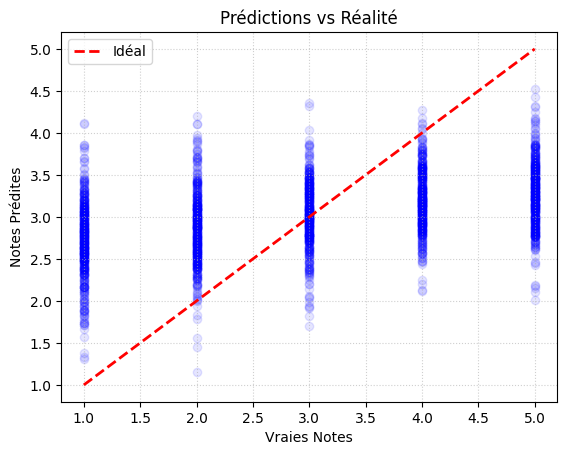

In [74]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Ridge(alpha=10))
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10,50,100,500],
    'classifier__alpha':[0.001, 0.01, 0.1, 0, 1, 10]
}

reg_search = GridSearchCV(model, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1,verbose=1)

calculateHyperParameters(reg_search,
                         x_train_local= x_train,
                         x_test_local=x_test,
                         y_train_local=y_train,
                         y_test_local=y_test)

### 2.2 Régression texte + catégorie - Ridge

Processeur : drop
Fitting 5 folds for each of 90 candidates, totalling 450 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 10}
Meilleure RMSE : 1.669
Mse: 1.6163830215828283
RMSE: 1.2713705288321058
R2 Score: 0.19262982183225907


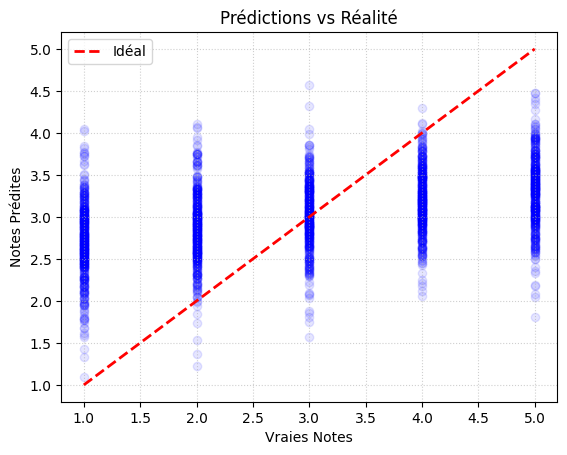

In [75]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
        ('category',OneHotEncoder(),['label'])
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Ridge(alpha=10))
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10,50,100,500],
    'classifier__alpha':[0.001, 0.01, 0.1, 0, 1, 10]
}

reg_search = GridSearchCV(model, param_grid, cv=5,scoring='neg_mean_squared_error',n_jobs=-1,verbose=1)

calculateHyperParameters(reg_search,
                         x_train_local= x_train,
                         x_test_local=x_test,
                         y_train_local=y_train,
                         y_test_local=y_test)

### 2.3 Régression par catégorie - Ridge


Processeur : drop
Lancement pour la catégorie Tools_and_Home_Improvement_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 10}
Meilleure RMSE : 2.087
Mse: 1.8465169421512244
RMSE: 1.3588660501135585
R2 Score: 0.13417548010748015


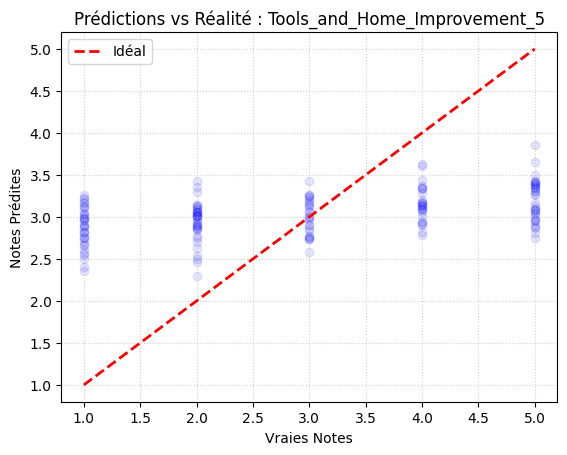

-------------------------
Lancement pour la catégorie Home_and_Kitchen_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 1, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 2}
Meilleure RMSE : 1.899
Mse: 2.0404213226784225
RMSE: 1.4284331705328124
R2 Score: 0.09383422361262717


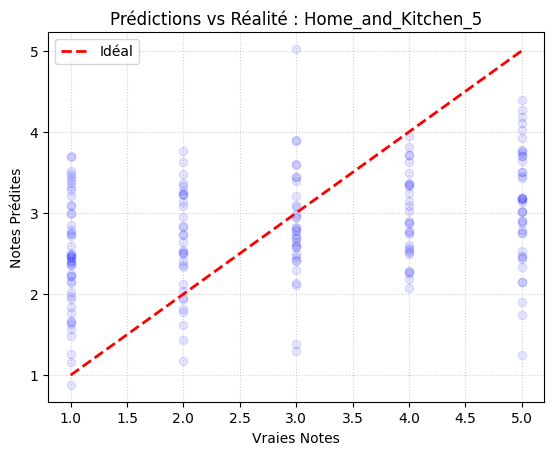

-------------------------
Lancement pour la catégorie Pet_Supplies_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 10}
Meilleure RMSE : 1.923
Mse: 2.08223789984759
RMSE: 1.4429961537882179
R2 Score: 0.06235824128397027


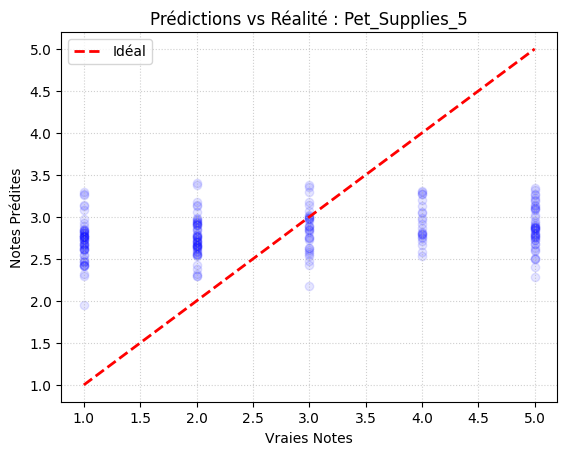

-------------------------
Lancement pour la catégorie Sports_and_Outdoors_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 1, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 2}
Meilleure RMSE : 1.840
Mse: 1.6641350884219612
RMSE: 1.29001360009186
R2 Score: 0.08512894727330134


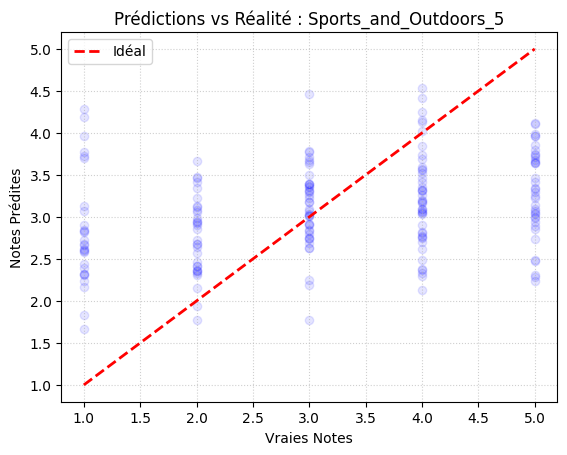

-------------------------
Lancement pour la catégorie Books_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 1, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 2}
Meilleure RMSE : 1.679
Mse: 1.588116914415241
RMSE: 1.2602051080737773
R2 Score: 0.10352825389636677


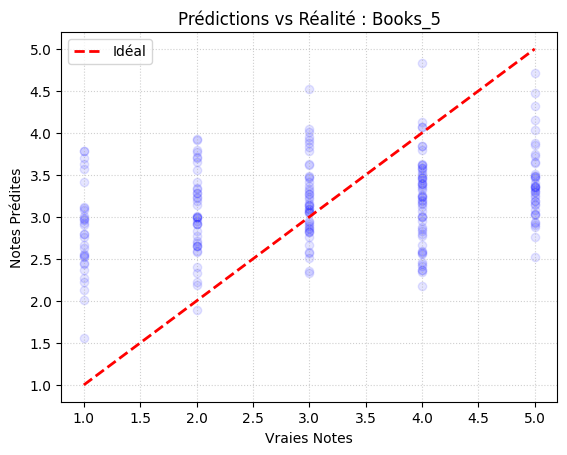

-------------------------
Lancement pour la catégorie Toys_and_Games_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 1, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 2}
Meilleure RMSE : 1.646
Mse: 1.683505678012308
RMSE: 1.2974997795808323
R2 Score: 0.13957473776833218


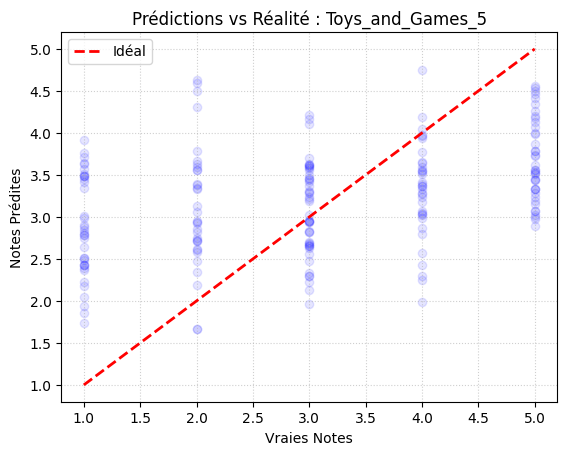

-------------------------
Lancement pour la catégorie Kindle_Store_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 1, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 2}
Meilleure RMSE : 1.403
Mse: 1.3930487342603544
RMSE: 1.180274855387657
R2 Score: 0.1299930199461209


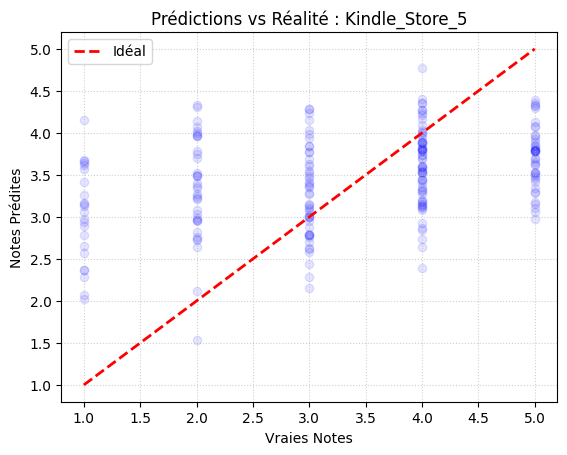

-------------------------
Lancement pour la catégorie Electronics_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 500, 'preprocessor__review__min_df': 10}
Meilleure RMSE : 1.925
Mse: 1.9862918962797562
RMSE: 1.409358682621197
R2 Score: 0.07645250330637343


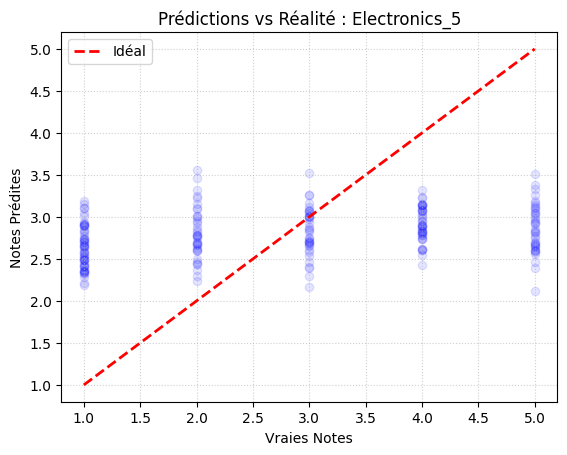

-------------------------
Lancement pour la catégorie Movies_and_TV_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 1000, 'preprocessor__review__min_df': 2}
Meilleure RMSE : 1.843
Mse: 1.6889203686295045
RMSE: 1.2995846908260749
R2 Score: 0.09325902550097531


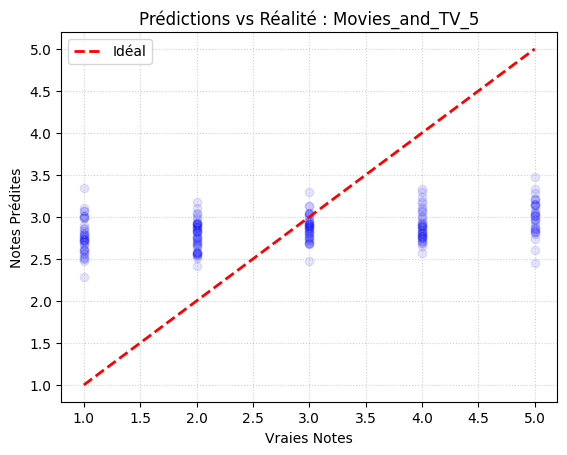

-------------------------
Lancement pour la catégorie Clothing_Shoes_and_Jewelry_5
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Meilleurs paramètres : {'classifier__alpha': 1, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 2}
Meilleure RMSE : 1.596
Mse: 1.9070347430966326
RMSE: 1.380954287113311
R2 Score: 0.06778880309304214


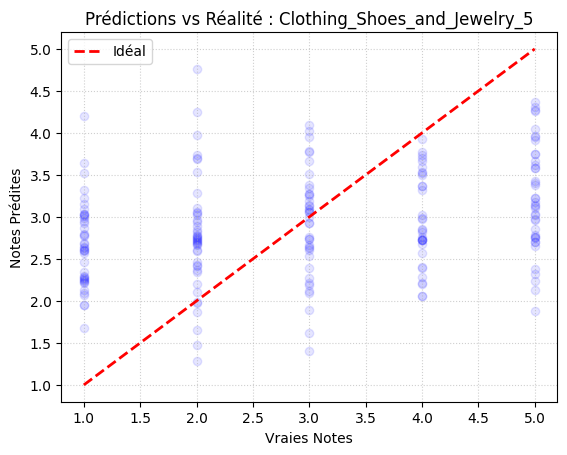

-------------------------
Résultats finaux
Meilleure RMSE: 1.180274855387657 pour la catégorie Kindle_Store_5
Meilleur score r2: 0.13957473776833218 pour la catégorie Toys_and_Games_5


In [76]:
# Isole toutes les catégories
categories = x_train['category'].unique() 


# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=100, # Garder les X termes plus importants
            min_df=50, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_')
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Ridge())
])

param_grid = {
    'preprocessor__review__max_features': [500,1000,2000],
    'preprocessor__review__min_df': [2, 10, 0.01, 0.05],
    'classifier__alpha':[0.001, 0.01, 0.1, 0, 1, 10]
}

reg_search_linear_regression = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1,
    error_score=np.nan
)

# Dictionnaire des résultats contenant la liste des résultats de chaque catégorie
results = {}

for category in categories:
    print(f"Lancement pour la catégorie {category}")
    cat_x_train, cat_x_test, cat_y_train, cat_y_test = isolateCategory(category,x_train,x_test,y_train,y_test)

    reg_search_linear_regression.fit(cat_x_train, cat_y_train)

    print(f"Meilleurs paramètres : {reg_search_linear_regression.best_params_}")
    print(f"Meilleure RMSE : {-reg_search_linear_regression.best_score_:.3f}")

    prediction_linear_regression = reg_search_linear_regression.best_estimator_.predict(cat_x_test) 

    # Ajout des résultats
    mse = mean_squared_error(cat_y_test,prediction_linear_regression)
    r2 = r2_score(cat_y_test,prediction_linear_regression)
    rmse = math.sqrt(mse)
    
    print(f"Mse: {mse}")
    print(f"RMSE: {rmse}")
    print(f"R2 Score: {r2}")
    plt.scatter(cat_y_test, prediction_linear_regression, color='blue', alpha=0.1)

    plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

    plt.title(f'Prédictions vs Réalité : {category}')
    plt.xlabel('Vraies Notes')
    plt.ylabel('Notes Prédites')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()
    results[category] = {"mse":mse,"rmse":rmse,"r2":r2}
    print("-------------------------")
    
# Analyse des résultats
print("Résultats finaux")
bestRmse = findBestRmse(results)
bestR2 = findBestR2(results)
print(f"Meilleure RMSE: {results[bestRmse]['rmse']} pour la catégorie {bestRmse}")

print(f"Meilleur score r2: {results[bestR2]['r2']} pour la catégorie {bestR2}")


### 2.5 Régression texte - Lasso

Processeur : drop
Fitting 5 folds for each of 105 candidates, totalling 525 fits
Meilleurs paramètres : {'classifier__alpha': 0.001, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 50}
Meilleure RMSE : 1.711
Mse: 1.6840440337360416
RMSE: 1.2977072218863706
R2 Score: 0.15883369634236377


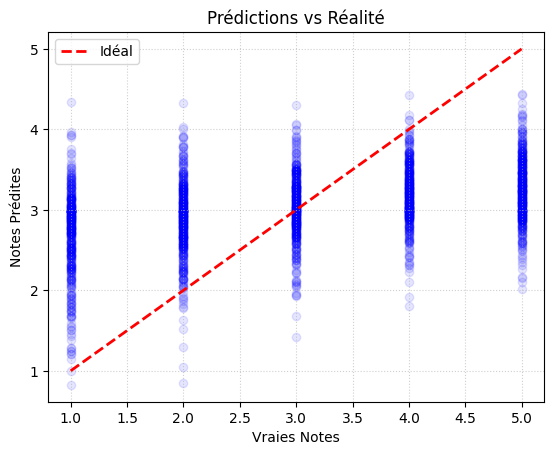

In [77]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Lasso(alpha=0.0001))
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10,50,100,500],
    'classifier__alpha': [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10]
}

reg_search = GridSearchCV(model, param_grid, cv=5,scoring='neg_mean_squared_error',n_jobs=-1,verbose=1)

calculateHyperParameters(reg_search,
                         x_train_local= x_train,
                         x_test_local=x_test,
                         y_train_local=y_train,
                         y_test_local=y_test)


## 3. Synthèse des expérimentations et des résultats obtenus

### Pré-traitements

Pour la parti pré-traitements nous avons choisi de reprendre le dataframe-brut afin de pouvoir le ré-équilibrer avec une distribution **uniforme**, c'est à dire avoir le même nombre d'avis à 5, 4, 3, 2 et 1.

Nous avons ensuite traiter le texte avec un filtrage POS avec spacy:
- On supprime les **stops words et la ponctuation**
- On garde uniquement les **adjectifs, adverbes, verbes et noms**
- On **lemmatise** la chaine de caractère final

Enfin nous utilisons des `Pipeline` afin de pouvoir faire un pré-traitement avec `TfidVectorizer`, les paramètres pré-traitements sont calculés lors de la recherche des hyperparamètres.

### Protocole d'expérimentations

Pour chacune des expérimentations la fonction `GridSearchCV` est utilisé afin de trouver les hyperparamètres, elle à pour instruction de se baser sur la `neg_mean_squared_error`, on utilise `neg` car par défaut la fonction cherche à obtenir la valeur la plus haute alors qu'ici on cherche la valeur la plus basse, on utilise la validation croisée avec `5` itérations pour obtenir une moyenne avec du sens.

Une fois les meilleurs paramètres trouvés on réalise l'entrainement et les prédictions sur ces derniers, enfin on affiche les métriques et les graphiques correspondant.

### Tableaux des paramètres

| Nom                        | max_features | min_df | ngram_ranges | stop_words | use_idf |
| -------------------------- | ------------ | ------ | ------------ | ---------- | ------- |
| Reg text toutes catégories | 2000         | 100    | 1,2          | english    | True    |
| Reg text + catégories      | 2000         | 100    | 1,2          | english    | True    |
| Reg text par catégories    | 500          | 0.05   | 1,2          | english    | True    |

### Tableaux des résultats

| Nom                        | MSE  | RMSE | R2    | Notes                      |
| -------------------------- | ---- | ---- | ----- | -------------------------- |
| Reg text toutes catégories | 1.69 | 1.3  | 0.15  |                            |
| Reg text + catégories      | 1.66 | 1.29 | 0.16  |                            |
| Reg text par catégories    | 1.59 | 1.26 | 0.002 | catégories: Kindle_Store_5 |

_Notes_: Les résultats de l'expérimentation `Reg text par catégories` sont ceux de la catégorie avec la meilleure RMSE, ici Kindle_Store_5.

**Conclusion:**
Malgré une légère amélioration par la segmentation des données, la régression linéaire se montre insufisante pour modéliser la complexité des avis textuels,
La RMSE ne descend pas en dessous pas de 1.10.

# Partie bonus

Dans cette partie nous avons utilisé le classifieur `Ridge` et `Lasso`

### Tableaux des paramètres

| Nom                           | max_features | min_df | ngram_ranges | alpha  | stop_words | use_idf |
| ----------------------------- | ------------ | ------ | ------------ | ------ | ---------- | ------- |
| Reg texte - Ridge             | 2000         | 10     | 1,2          | 10     | english    | True    |
| Reg texte + categorie - Ridge | 2000         | 10     | 1,2          | 10     | english    | True    |
| Reg text par catégories       | 2000         | 2      | 1,2          | 1      | english    | True    |
| Reg texte - Lasso             | 2000         | 50     | 1,2          | 0.0001 | english    | True    |

### Tableaux des résultats

| Nom                              | MSE  | RMSE | R2   | Notes                     |
| -------------------------------- | ---- | ---- | ---- | ------------------------- |
| Reg texte - Ridge                | 1.64 | 1.28 | 0.18 |                           |
| Reg texte + catégorie - Ridge    | 1.61 | 1.27 | 0.2  |                           |
| Reg texte par catégories - Ridge | 1.39 | 1.18 | 0.12 | catégorie: Kindle_Store_5 |
| Reg texte - Lasso                | 1.68 | 1.68 | 0.15 |                           |

---

**Conclusion**:
L'utilisation du modèle `Ridge` et `Lasso` nous permet de gagner en précision lors de la régression

# Conclusion général

Les différentes expérimentations menées montrent que l'ajustement des paramètres ne suffit pas à améliorer les scores de régression. La réduction du volume de données à 9 835 lignes, nécessaire pour obtenir une distribution uniforme, semble avoir créé un goulot d'étranglement. Ce manque de données limite la capacité d'apprentissage des modèles, rendant les résultats peu concluant malgré l'optimisations des différentes paramètres de traitements.

Afin d'améliorer nos analyses nous devrions mettre en place un traitement plus rigoureux avec spacy en utilisant d'autres métriques plus avancées comme la densité lexicale, l'analyse des dépendance syntaxiques afin de fournir à notre modèles des textes plus discriminants.


